# 04 — The 2023 Shock
**Stage:** Description

**TL;DR:** Demand in Aug–Oct 2023 was **+33% to +56%** above 2022. The extra load sat in **farm-pumping hours (day +60%, night +54%)**, while the **evening rose +24% — about the same as 2024 (+21%) and 2025 (+26%)** when the scheme ran with normal rain. The load **rose and fell with rainfall week by week, both before and after 1 Aug** — something a constant policy cannot do. But 2023 was also the **driest (256 mm) and hottest** Aug–Oct in the data, so heat must be controlled for before claiming the cause.

## 1. Question
What exactly happened to Karnataka's electricity demand in the second half of 2023?

1. **How big** was the jump, month by month, compared with other years?
2. **When** did it start — before or after Gruha Jyothi began (1 Aug 2023)?
3. **In which hours** did the extra demand appear? (first look at the "fingerprint")
4. **How dry** was 2023, and how hot? (the two weather conditions that could explain it)
5. **How was it supplied** — which sources filled the gap?

Still *description only*: this notebook measures what happened; Notebooks 05–07 test why.

## 2. Expectation *(written before running)*
From the quick exploration during project research:
- Aug 2023 load ≈ **+48%** vs Aug 2022, Oct ≈ **+56%**.
- Extra demand concentrated in **daytime (+55–65%) and night (+55%)**, much less in the **evening (+20%)**.
- In 2024 (normal rain, scheme still running) the hourly increase should be **flatter (~+25–30% everywhere)**.
- Farm-belt rain in Aug–Oct 2023 ≈ **250 mm vs ~600 mm** in normal years.
- Linganamakki reservoir ≈ **42% full in Nov 2023** (lowest in 15 years).
- I have **no expectation yet** about exactly when the jump started — this is the most important open question here.

## 3. Data used
`load_hourly`, `weather_daily`, `weather_hourly_blr`, `reservoirs_daily`, `generation_daily` (all from `data/processed/`).
Comparison years: **2021, 2022** (before scheme, normal monsoon), **2023** (scheme + drought), **2024, 2025**
(scheme, normal monsoon). The hourly data for 2023 only exists from **13 July**.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src import config, plots

plots.setup()
pd.set_option("display.width", 200)

load = pd.read_parquet(config.DATA_PROCESSED / "load_hourly.parquet")
wx = pd.read_parquet(config.DATA_PROCESSED / "weather_daily.parquet")
wxh = pd.read_parquet(config.DATA_PROCESSED / "weather_hourly_blr.parquet")
res = pd.read_parquet(config.DATA_PROCESSED / "reservoirs_daily.parquet")
gen = pd.read_parquet(config.DATA_PROCESSED / "generation_daily.parquet")

YEARS = [2021, 2022, 2023, 2024, 2025]
YEAR_COLORS = {2021: "#9ecae1", 2022: "#4292c6", 2023: plots.COLORS["highlight"], 2024: "#74c476", 2025: "#238b45"}
SCHEME = pd.Timestamp(config.SCHEME_START)

hrs = load.load_mw.resample("D").count()
daily = load.load_mw.resample("D").mean().where(hrs >= 20)     # daily average MW, only near-complete days

## 4. Analysis
### Step 4.1 — How big was the jump?
*Why:* first establish the size of the event before trying to explain it.

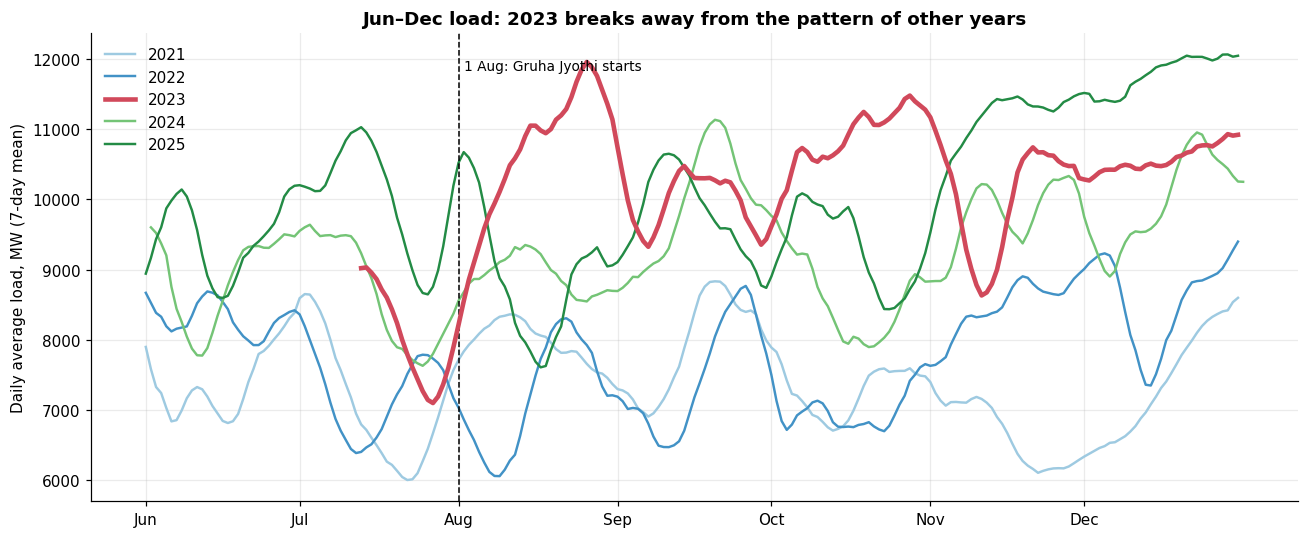

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
for yr in YEARS:
    s = daily[f"{yr}-06-01":f"{yr}-12-31"].rolling(7, center=True, min_periods=4).mean()
    x = s.index.dayofyear
    ax.plot(x, s.values, color=YEAR_COLORS[yr], lw=3 if yr == 2023 else 1.6, label=str(yr), zorder=3 if yr == 2023 else 2)
ax.axvline(SCHEME.dayofyear, color="black", ls="--", lw=1)
ax.text(SCHEME.dayofyear + 1, ax.get_ylim()[1] * 0.97, "1 Aug: Gruha Jyothi starts", va="top", fontsize=9)
month_starts = [pd.Timestamp(f"2023-{m:02d}-01").dayofyear for m in range(6, 13)]
ax.set_xticks(month_starts, ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Daily average load, MW (7-day mean)")
ax.set_title("Jun–Dec load: 2023 breaks away from the pattern of other years")
ax.legend()
plt.tight_layout(); plots.save(fig, "04_jun_dec_by_year"); plt.show()

In [3]:
mon = load.load_mw.groupby([load.index.year, load.index.month]).mean().unstack()
mon = mon.loc[YEARS, 7:12]
vs22 = ((mon / mon.loc[2022] - 1) * 100).round(0)
print("Average load (MW), Jul–Dec:")
print(mon.round(-1).to_string())
print("\nChange vs same month of 2022 (%):")
print(vs22.to_string())

Average load (MW), Jul–Dec:
datetime       7        8       9        10       11       12
datetime                                                     
2021       7110.0   7930.0  7950.0   7270.0   6660.0   7390.0
2022       7230.0   7200.0  7520.0   6950.0   8430.0   8630.0
2023       7970.0  10690.0  9970.0  10820.0  10070.0  10570.0
2024       8650.0   8930.0  9890.0   8620.0   9790.0   9930.0
2025      10000.0   8950.0  9780.0   9290.0  11070.0  11810.0

Change vs same month of 2022 (%):
datetime    7     8     9     10    11    12
datetime                                    
2021      -2.0  10.0   6.0   5.0 -21.0 -14.0
2022       0.0   0.0   0.0   0.0   0.0   0.0
2023      10.0  49.0  33.0  56.0  19.0  22.0
2024      20.0  24.0  32.0  24.0  16.0  15.0
2025      38.0  24.0  30.0  34.0  31.0  37.0


_What I see:_ see Result.

### Step 4.2 — When did it start?
*Why:* if demand jumped **exactly on 1 Aug**, that points to the scheme; if it rose **gradually as the rain
failed**, that points to the drought; if it started **before 1 Aug**, the scheme cannot be the trigger.

Method: compare each day of 2023 with the **same weekday one year earlier** (364 days before), using a 7-day
average to smooth out noise.

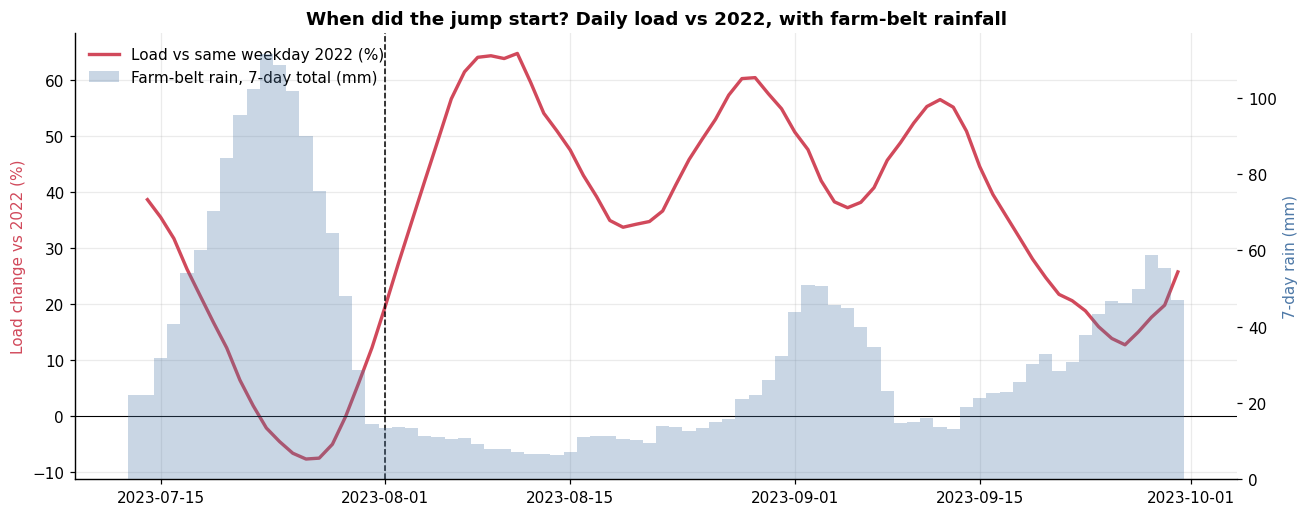

In [4]:
d7 = daily.rolling(7, center=True, min_periods=5).mean()
ratio = (d7 / d7.shift(364) - 1) * 100               # vs same weekday last year
r23 = ratio["2023-07-13":"2023-09-30"]

farm_rain = wx.farm_rain_mm
rain7 = farm_rain.rolling(7, center=True).sum()

fig, ax1 = plt.subplots(figsize=(12, 4.8))
ax1.plot(r23.index, r23.values, color=plots.COLORS["highlight"], lw=2.2, label="Load vs same weekday 2022 (%)")
ax1.axhline(0, color="black", lw=0.7)
ax1.axvline(SCHEME, color="black", ls="--", lw=1)
ax1.set_ylabel("Load change vs 2022 (%)", color=plots.COLORS["highlight"])
ax2 = ax1.twinx()
rr = rain7["2023-07-13":"2023-09-30"]
ax2.bar(rr.index, rr.values, color=plots.COLORS["hydro"], alpha=0.3, width=1, label="Farm-belt rain, 7-day total (mm)")
ax2.set_ylabel("7-day rain (mm)", color=plots.COLORS["hydro"])
ax2.grid(False)
ax1.set_title("When did the jump start? Daily load vs 2022, with farm-belt rainfall")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plots.save(fig, "04_when_did_it_start"); plt.show()

In [5]:
weekly = pd.DataFrame({
    "load_vs_2022_%": ratio["2023-07-13":"2023-09-30"].resample("W-SUN").mean().round(1),
    "farm_rain_mm_week": farm_rain["2023-07-13":"2023-09-30"].resample("W-SUN").sum().round(0),
    "farm_rain_mm_week_2022": farm_rain["2022-07-14":"2022-10-01"].resample("W-SAT").sum().round(0).values[:12],
})
weekly

,load_vs_2022_%,farm_rain_mm_week,farm_rain_mm_week_2022
2023-07-16,35.3,14.0,21.0
2023-07-23,11.9,84.0,38.0
2023-07-30,-3.6,76.0,50.0
2023-08-06,34.6,14.0,108.0
2023-08-13,61.8,8.0,47.0
2023-08-20,40.6,11.0,11.0
2023-08-27,45.5,13.0,46.0
2023-09-03,53.4,32.0,60.0
2023-09-10,43.1,35.0,84.0
2023-09-17,48.3,19.0,22.0


### Step 4.3 — In which hours did the extra demand appear?
*Why:* households use power mostly in the **evening**; farm pumps run in the **day and night** supply slots.
Growth by hour (Aug–Oct, compared with 2022) is the first look at the fingerprint.

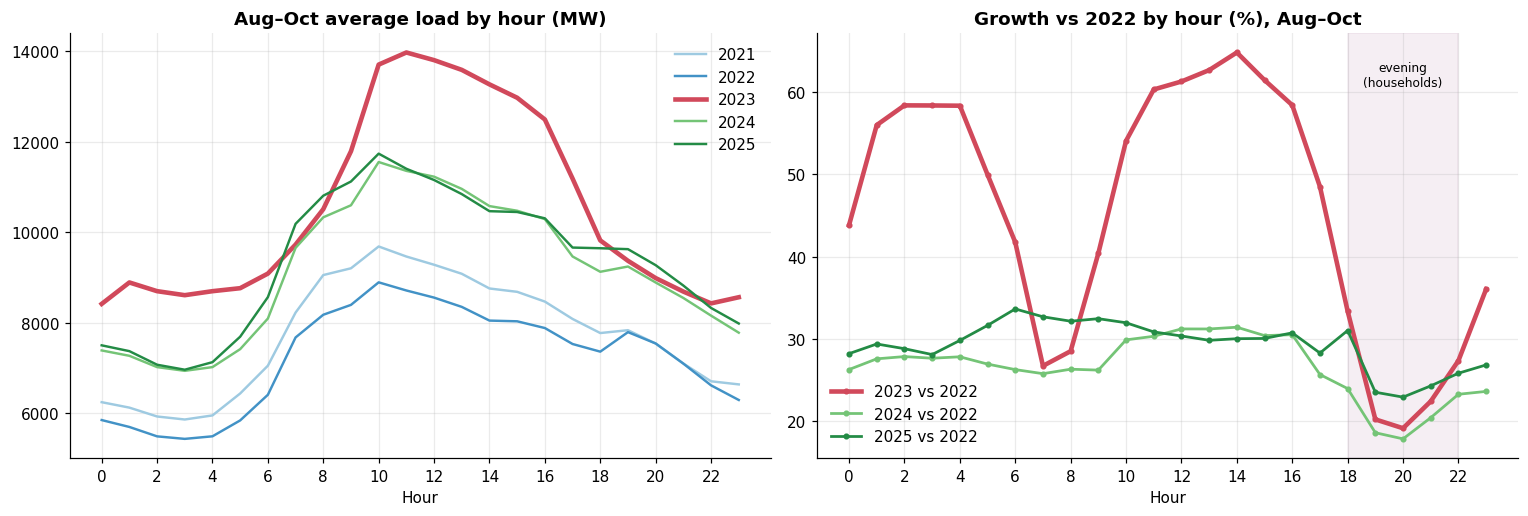

,2021 vs 2022 (%),2023 vs 2022 (%),2024 vs 2022 (%),2025 vs 2022 (%)
night 0–5h,8.0,54.0,27.0,29.0
morning 6–9h,9.0,34.0,26.0,33.0
day 10–16h,8.0,60.0,31.0,31.0
evening 18–22h,1.0,24.0,21.0,26.0


In [6]:
sub = load[load.index.month.isin([8, 9, 10])]
prof = sub.load_mw.groupby([sub.index.year, sub.index.hour]).mean().unstack(0)
growth = (prof.div(prof[2022], axis=0) - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for yr in [2021, 2022, 2023, 2024, 2025]:
    axes[0].plot(prof.index, prof[yr], color=YEAR_COLORS[yr], lw=3 if yr == 2023 else 1.6, label=str(yr))
axes[0].set_title("Aug–Oct average load by hour (MW)"); axes[0].set_xlabel("Hour"); axes[0].legend()
for yr in [2023, 2024, 2025]:
    axes[1].plot(growth.index, growth[yr], color=YEAR_COLORS[yr], lw=3 if yr == 2023 else 1.8, marker="o", ms=3, label=f"{yr} vs 2022")
axes[1].axvspan(18, 22, color="#b07aa1", alpha=0.12)
axes[1].text(20, axes[1].get_ylim()[1] * 0.95, "evening\n(households)", ha="center", va="top", fontsize=8)
axes[1].set_title("Growth vs 2022 by hour (%), Aug–Oct"); axes[1].set_xlabel("Hour"); axes[1].legend()
for ax in axes: ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plots.save(fig, "04_hourly_fingerprint"); plt.show()

blocks = {"night 0–5h": range(0, 6), "morning 6–9h": range(6, 10), "day 10–16h": range(10, 17),
          "evening 18–22h": range(18, 23)}
tbl = pd.DataFrame({b: growth.loc[list(h)].mean() for b, h in blocks.items()}).T[[2021, 2023, 2024, 2025]].round(0)
tbl.columns = [f"{c} vs 2022 (%)" for c in tbl.columns]
tbl

In [7]:
# Same check for Nov–Dec (after the main monsoon season)
sub2 = load[load.index.month.isin([11, 12])]
prof2 = sub2.load_mw.groupby([sub2.index.year, sub2.index.hour]).mean().unstack(0)
g2 = (prof2.div(prof2[2022], axis=0) - 1) * 100
pd.DataFrame({b: g2.loc[list(h)].mean() for b, h in blocks.items()}).T[[2023, 2024, 2025]].round(0)

datetime,2023,2024,2025
night 0–5h,30.0,15.0,36.0
morning 6–9h,22.0,19.0,36.0
day 10–16h,19.0,14.0,35.0
evening 18–22h,15.0,16.0,30.0


### Step 4.4 — How dry was 2023? How hot?
*Why:* these are the weather conditions that could raise demand without any policy change. Rain matters for
farm pumping; temperature matters for fans and air conditioners.

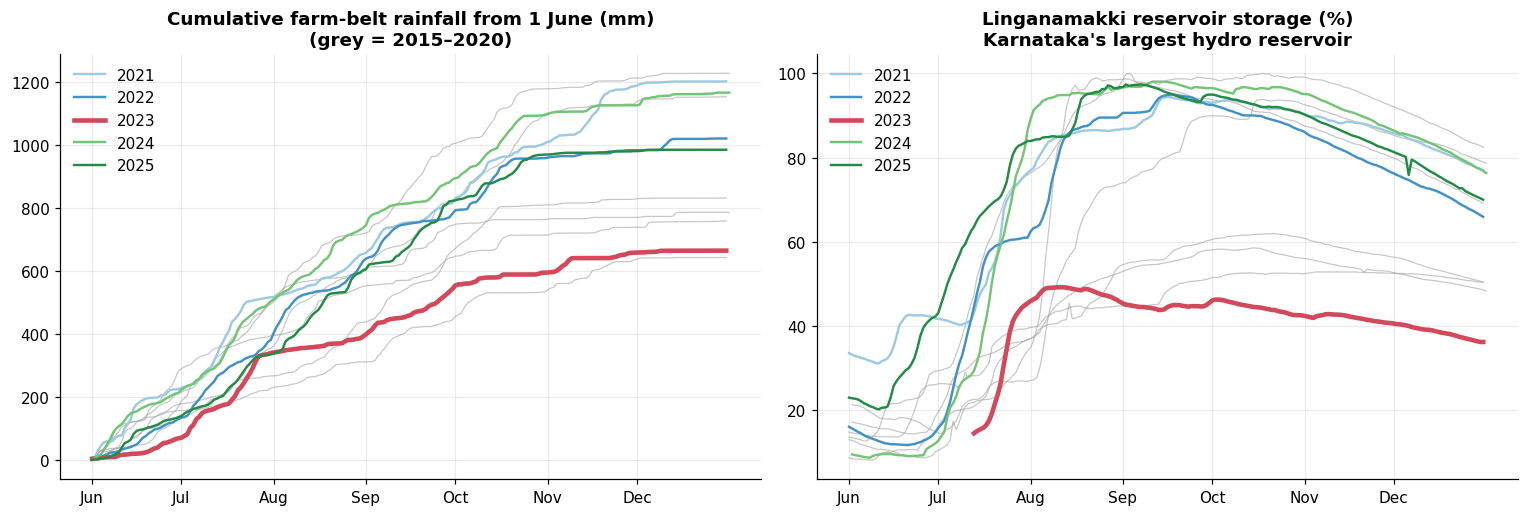

,Jun–Jul rain (mm),Aug–Oct rain (mm),Nov–Dec rain (mm),Linganamakki 1 Nov (%)
2015,228.0,306.0,110.0,52.0
2016,515.0,250.0,22.0,56.0
2017,268.0,543.0,22.0,61.0
2018,394.0,320.0,45.0,88.0
2019,355.0,745.0,54.0,99.0
2020,504.0,675.0,49.0,92.0
2021,518.0,489.0,197.0,90.0
2022,382.0,578.0,62.0,86.0
2023,340.0,256.0,70.0,42.0
2024,510.0,589.0,68.0,95.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for yr in range(2015, 2026):
    s = farm_rain[f"{yr}-06-01":f"{yr}-12-31"].cumsum()
    c = YEAR_COLORS.get(yr, plots.COLORS["muted"])
    axes[0].plot(s.index.dayofyear, s.values, color=c, lw=3 if yr == 2023 else (1.6 if yr in YEAR_COLORS else 0.8),
                 label=str(yr) if yr in YEAR_COLORS else None, alpha=1 if yr in YEAR_COLORS else 0.6)
axes[0].set_xticks(month_starts := [pd.Timestamp(f"2023-{m:02d}-01").dayofyear for m in range(6, 13)],
                   ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axes[0].set_title("Cumulative farm-belt rainfall from 1 June (mm)\n(grey = 2015–2020)"); axes[0].legend()

ling = res[res.reservoir == "Linganamakki"].set_index("date").storage_pct.sort_index()
for yr in range(2015, 2026):
    s = ling[f"{yr}-06-01":f"{yr}-12-31"]
    c = YEAR_COLORS.get(yr, plots.COLORS["muted"])
    axes[1].plot(s.index.dayofyear, s.values, color=c, lw=3 if yr == 2023 else (1.6 if yr in YEAR_COLORS else 0.8),
                 label=str(yr) if yr in YEAR_COLORS else None, alpha=1 if yr in YEAR_COLORS else 0.6)
axes[1].set_xticks(month_starts, ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axes[1].set_title("Linganamakki reservoir storage (%)\nKarnataka's largest hydro reservoir"); axes[1].legend()
plt.tight_layout(); plots.save(fig, "04_drought"); plt.show()

rain_tbl = pd.DataFrame({
    "Jun–Jul rain (mm)": [farm_rain[f"{y}-06-01":f"{y}-07-31"].sum() for y in range(2015, 2026)],
    "Aug–Oct rain (mm)": [farm_rain[f"{y}-08-01":f"{y}-10-31"].sum() for y in range(2015, 2026)],
    "Nov–Dec rain (mm)": [farm_rain[f"{y}-11-01":f"{y}-12-31"].sum() for y in range(2015, 2026)],
    "Linganamakki 1 Nov (%)": [ling.asof(pd.Timestamp(f"{y}-11-01")) for y in range(2015, 2026)],
}, index=range(2015, 2026)).round(0)
rain_tbl

In [9]:
t = wxh.blr_temp_c
temp_tbl = pd.DataFrame({
    "Bengaluru Aug–Oct mean temp (°C)": [t[f"{y}-08-01":f"{y}-10-31"].mean() for y in YEARS],
    "Bengaluru Aug–Oct mean daily max (°C)": [wx.blr_tmax_c[f"{y}-08-01":f"{y}-10-31"].mean() for y in YEARS],
    "Farm-belt Aug–Oct mean daily max (°C)": [wx.farm_tmax_c[f"{y}-08-01":f"{y}-10-31"].mean() for y in YEARS],
}, index=YEARS).round(1)
temp_tbl

,Bengaluru Aug–Oct mean temp (°C),Bengaluru Aug–Oct mean daily max (°C),Farm-belt Aug–Oct mean daily max (°C)
2021,22.6,27.1,28.3
2022,22.0,26.7,27.9
2023,23.8,29.2,30.4
2024,22.9,27.7,28.6
2025,22.5,26.9,28.2


### Step 4.5 — How was the extra demand supplied?
*Why:* the supply side shows the strain on the system (and gives the drought a second fingerprint: low
reservoirs → less hydro power).

In [10]:
g = gen[gen.index.month.isin([8, 9, 10, 11, 12])]
supply = g.groupby(g.index.year)[["coal", "hydro", "solar", "wind", "central_import", "total"]].mean().loc[YEARS].round(1)
print("Average daily energy, Aug–Dec (MU/day):")
supply

Average daily energy, Aug–Dec (MU/day):


,coal,hydro,solar,wind,central_import,total
date,,,,,,
2021,53.0,37.4,30.5,20.7,42.8,178.4
2022,34.9,38.4,32.5,19.6,51.9,185.6
2023,71.4,25.3,37.1,24.0,71.0,250.1
2024,56.8,47.0,35.4,21.2,58.9,226.2
2025,64.4,45.7,37.1,26.5,48.4,244.3


## 5. Result
**1. Size of the jump (vs same month of 2022)**
| | Jul | Aug | Sep | Oct | Nov | Dec |
|---|---|---|---|---|---|---|
| 2023 | +10% | **+49%** | +33% | **+56%** | +19% | +22% |
| 2024 | +20% | +24% | +32% | +24% | +16% | +15% |
| 2025 | +38% | +24% | +30% | +34% | +31% | +37% |

Aug and Oct 2023 stand far above both the years before and the years after. Note that **by 2025, demand had caught up** with 2023's level through normal growth.

**2. When did it start?** *(chart `04_when_did_it_start`)*
- **Before the scheme:** in mid-July 2023 (dry spell) load was already **+35–39%** above 2022. Then **heavy rain in late July** pushed it down to **−7%** — *below* 2022 — just before 1 Aug.
- **Around 1 Aug:** the rain stopped at almost exactly the same time the scheme started, and load shot up to **+65%** by mid-August. Timing alone **cannot separate** the two causes here.
- **After 1 Aug:** every rainy spell (early Sep, late Sep) **pulled load growth down** (to +37% and +13%), and every dry spell pushed it back up. The scheme was constant during this time, so it cannot explain these swings; rain can.

**3. The hourly fingerprint (Aug–Oct, vs 2022)**
| Hours | 2023 | 2024 | 2025 |
|---|---|---|---|
| Night 0–5h | **+54%** | +27% | +29% |
| Morning 6–9h | +34% | +26% | +33% |
| Day 10–16h | **+60%** | +31% | +31% |
| **Evening 18–22h** | **+24%** | **+21%** | **+26%** |

In 2024–25 growth is **flat across the day (~+25–31%)**. In 2023 the extra appears **only in day and night hours** — the scheduled farm-pump supply slots — while the **evening (household) increase matches 2024–25**. There's a clear dip at 7–8 am (pump shift change) and 6–9 pm (household peak).

In **Nov–Dec 2023**, the extra was much smaller (+15% to +30%) and mostly at **night**.

**4. Weather**
- Farm-belt rain Aug–Oct 2023: **256 mm**, the lowest since 2016 (250 mm) and **less than half** of 2022 (578) or 2024 (589).
- **Linganamakki reservoir on 1 Nov 2023: 42%**, the lowest in the dataset (normally 86–99%).
- **2023 was also hotter:** Bengaluru Aug–Oct average daily max **29.2 °C vs 26.7–27.7 °C** in other years (+2 °C). Dry weather means fewer clouds and more heat, so drought and heat arrived together.

**5. Supply:** hydro fell (25 vs 38–47 MU/day), so the extra demand was met by **coal doubling vs 2022 (71 vs 35 MU/day)** and more central/imported power (71 vs 52).

**My expectations vs results:** size ✓, hourly pattern ✓ (day +60, night +54, evening +24 — very close), 2024 flatter ✓, rain ~250 mm ✓, reservoir 42% ✓. **New:** load tracked rain week by week, before and after 1 Aug. **New problem:** 2023 was ~2 °C hotter.

Figures: `04_jun_dec_by_year`, `04_when_did_it_start`, `04_hourly_fingerprint`, `04_drought`.

## 6. Caveats
- **Comparing with 2022 includes 2022's own weather.** For example, heavy rain in early Aug 2022 made 2022's load low, which inflates the 2023-vs-2022 ratio in mid-August. Notebook 05 fixes this with a model that accounts for weather in both years.
- **Heat is a competing explanation** for part of the daytime surge (fans/air conditioners). Notebooks 05–06 must control for temperature.
- Year-on-year comparisons also contain **normal demand growth** (~4–6% a year). The 2024 and 2025 rows show growth + scheme together, not the scheme alone.
- The **timing around 1 Aug** cannot separate the causes, because the rain stopped at almost the same time.
- The "evening = households, day/night = farms" mapping is approximate: households also use power during the day, and some pumps may run in the evening.
- **2016** was nearly as dry (250 mm) but had no free-power scheme — a possible natural comparison for Notebook 07 (though the farm supply schedule was different back then).

## 7. Next
**Notebook 05 — Counterfactual model** (Evaluation):
- Train a model on **2015–2022 only** that predicts hourly load from trend, hour, weekday, month, holidays, **temperature and rainfall**.
- Predict Aug–Dec 2023 (and 2024–25) as if nothing unusual had happened.
- **Excess = actual − predicted.** This removes normal growth and weather effects (including the heat), so we can see what is left to explain.